In [11]:
pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster               import KMeans
from sklearn.metrics               import silhouette_score
from sklearn.decomposition         import PCA

In [13]:
# 1. Load the CSV
df = pd.read_csv("/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_search_results.csv", usecols=["Summary"])
df = df.dropna(subset=["Summary"]).reset_index(drop=True)
df.describe()

,Summary
count,3489
unique,3465
top,The Arctic Sounder - Serving the Northwest Arc...
freq,8


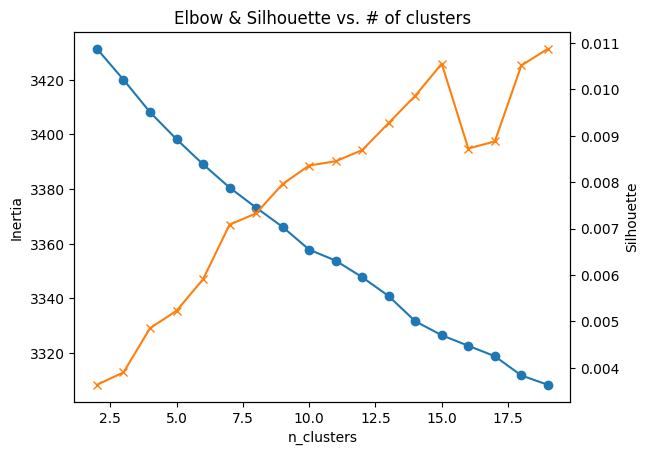

Cluster 0: fish, game, department, alaska, year, salmon, said, wildlife, caught, bay, river, state, biologist, bears, dead, officials, king, species, commercial, harvest, fishing, sockeye, says, people, crab, bear, black, low, biologists, local, catch, number, area, invasive, lake, 000, unusual, chinook, week, near, numbers, new, reported, fewer, bristol, years, returns, kenai, summer, net, impact, cook, fishery, sick, tularemia, run, far, cause, according, don, 2024, halibut, red, inlet, southeast, population, season, point, way, hundreds, news, fisherman, magazine, gear, camps, came, trying, help, fishermen, returned, rotenone, bend, seeing, time, seen, spawning, good, recent, unknown, killed, proposal, kasilof, appears, like, allowed, chum, creek, anglers, anchorage, yukon
Cluster 1: sea, ice, bering, alaska, dead, northern, coast, crab, scientists, ocean, region, otter, star, beach, nome, arctic, strait, near, observed, lion, island, western, north, stars, lions, like, reported, un

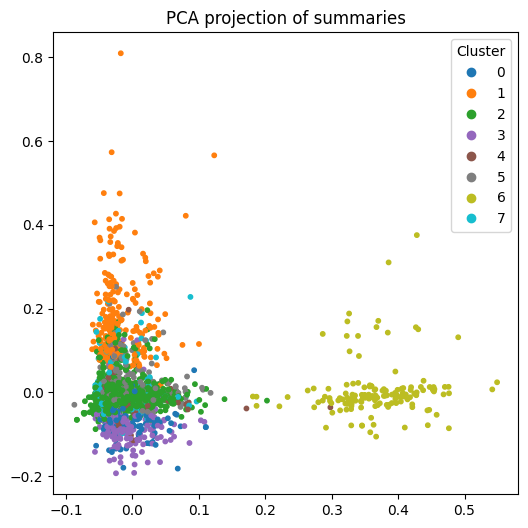

In [14]:

# 2. Vectorize with TF–IDF
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_df=0.9,     # drop very common tokens
    min_df=2        # drop rare tokens
)
X = tfidf.fit_transform(df["Summary"])

# 3. Choose k: elbow & silhouette
ks       = list(range(2,20))
inertia  = []
sil_score= []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=100)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    sil_score.append(silhouette_score(X, labels))

fig, ax1 = plt.subplots()
ax1.plot(ks, inertia, marker="o")
ax1.set_ylabel("Inertia")
ax2 = ax1.twinx()
ax2.plot(ks, sil_score, marker="x", color="C1")
ax2.set_ylabel("Silhouette")
ax1.set_xlabel("n_clusters")
plt.title("Elbow & Silhouette vs. # of clusters")
plt.show()

# → pick the k where inertia “elbows” and silhouette peaks (say k_opt)

k_opt = 8   # ← for example
km = KMeans(n_clusters=k_opt, random_state=42, n_init=100)
df["cluster"] = km.fit_predict(X)

# 4. Inspect top terms per cluster
terms = np.array(tfidf.get_feature_names_out())
order_centroids = km.cluster_centers_.argsort()[:, ::-1]

for i in range(k_opt):
    top_terms = terms[order_centroids[i, :100]]
    print(f"Cluster {i}: {', '.join(top_terms)}")

# 5. (Optional) 2D projection for sanity check
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X.toarray())

plt.figure(figsize=(6,6))
scatter = plt.scatter(coords[:,0], coords[:,1], c=df["cluster"], cmap="tab10", s=10)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.title("PCA projection of summaries")
plt.show()